In [1]:
import pandas as pd
import numpy as np
import seaborn as sns

print("pandas:", pd.__version__, "numpy:", np.__version__, "seaborn:", sns.__version__)

pandas: 3.1.1 numpy: 2.5.5 seaborn: 0.13.2


In [2]:
df = sns.load_dataset('titanic')
df.head(5)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
# 데이터 shape 조회
df.shape

(891, 15)

In [4]:
# 자료형 조회
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


In [5]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [6]:
# 각 셀의 널 여부
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [7]:
# 나이가 비어있는 승객 수, 성별, 클래스
empty_age = df["age"].isnull()
print("나이 빈칸:", empty_age.sum(), "명")
df.loc[empty_age, ["sex", "age", "class"] ].head()

나이 빈칸: 177 명


,sex,age,class
5,male,NaN,Third
17,male,NaN,Second
19,female,NaN,Third
26,male,NaN,Third
28,female,NaN,Third


In [8]:
# 평균값, 중앙값 산출
print("평균", round(df["age"].mean(), 2))
print("중앙값", round(df["age"].median(), 2))

mean_age = df["age"].mean()
# fillna : 빈칸(NaN)만 주어진 값을 새로운 값으로 채우는 메소드 df["열"] = df["열"].fillna(새로운값)
df.loc[:, "age"] = df["age"].fillna(mean_age)

# df["age"].isnull().sum()
df.loc[empty_age, ["sex", "age", "class"] ].head()

평균 29.7
중앙값 28.0


,sex,age,class
5,male,29.699118,Third
17,male,29.699118,Second
19,female,29.699118,Third
26,male,29.699118,Third
28,female,29.699118,Third


In [9]:
# 탑승 항구 : 최빈값
df["embark_town"].value_counts(dropna=False)

embark_town
Southampton    644
Cherbourg      168
Queenstown      77
NaN              2
Name: count, dtype: int64

In [10]:
# 최빈값 추출후 빈칸에 채우는 로직
mode_town = df["embark_town"].mode()[0]
print("최빈값:", mode_town)

df.loc[:, "embark_town"] = df["embark_town"].fillna(mode_town)
df["embark_town"].value_counts(dropna=False)

최빈값: Southampton


embark_town
Southampton    646
Cherbourg      168
Queenstown      77
Name: count, dtype: int64

In [11]:
# embarked town 값으로 설정
df.loc[:, "embarked"] = df["embark_town"].str[0]
df[["embarked","embark_town"]].isnull().sum()

embarked       0
embark_town    0
dtype: int64

In [12]:
# print(df["deck"].dtype)
# df["deck"].cat.categories

# df["deck"].cat.add_categories("Unknown")
# df["deck"] = df["deck"].fillna("Unknown")

# df["deck"] = df["deck"].cat.add_categories("Unknown").fillna("Unknown")

print(df["deck"].cat.categories.to_list())
print(df["deck"].value_counts())

['A', 'B', 'C', 'D', 'E', 'F', 'G']
deck
C    59
B    47
D    33
E    32
A    15
F    13
G     4
Name: count, dtype: int64


In [13]:
df.isnull().sum()

survived         0
pclass           0
sex              0
age              0
sibsp            0
parch            0
fare             0
embarked         0
class            0
who              0
adult_male       0
deck           688
embark_town      0
alive            0
alone            0
dtype: int64

In [14]:
# 튀는 값 확인

print(df["fare"].quantile([0.25, 0.5, 0.75]))
df["fare"].describe()[["25%", "50%", "75%"]]

# IQR 계산 (Q3 -Q1)
# 이상수치 Q3 + 1.5*IQR

q1 = df["fare"].quantile(0.25)
q3 = df["fare"].quantile(0.75)
iqr = q3 - q1
upper = q3 + 1.5*iqr
# Q1, Q3, IQP, UPPER
print (f"Q1={q1:.2f}, Q3={q3:.2f} IQR={iqr:.2f} UPPER={upper:.2f}")
print("이상 승선요금:", (df["fare"] > upper).sum(), "명")

0.25     7.9104
0.50    14.4542
0.75    31.0000
Name: fare, dtype: float64
Q1=7.91, Q3=31.00 IQR=23.09 UPPER=65.63
이상 승선요금: 116 명


In [15]:
df[ df["fare"] > 512 ]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
258,1,1,female,35.0,0,0,512.3292,C,First,woman,False,NaN,Cherbourg,yes,True
679,1,1,male,36.0,0,1,512.3292,C,First,man,True,B,Cherbourg,yes,False
737,1,1,male,35.0,0,0,512.3292,C,First,man,True,B,Cherbourg,yes,True


In [16]:
before = len(df)
df = df [ df["fare"] < 512].copy()
print(before, "=>", len(df))

891 => 888


In [17]:
# 중복되는 행 확인

print("중복 행:", df.duplicated().sum(), "개")
df[df.duplicated(keep=False)].sort_values(["fare", "age"]).head(5)  

중복 행: 107 개


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
277,0,2,male,29.699118,0,0,0.0,S,Second,man,True,NaN,Southampton,no,True
413,0,2,male,29.699118,0,0,0.0,S,Second,man,True,NaN,Southampton,no,True
466,0,2,male,29.699118,0,0,0.0,S,Second,man,True,NaN,Southampton,no,True
481,0,2,male,29.699118,0,0,0.0,S,Second,man,True,NaN,Southampton,no,True
674,0,2,male,29.699118,0,0,0.0,S,Second,man,True,NaN,Southampton,no,True


Text(0.5, 0, '나이(세)')

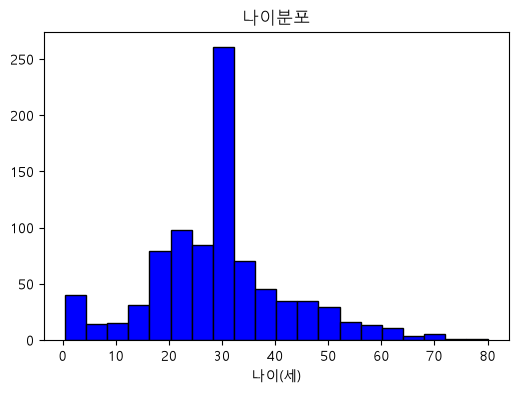

In [18]:
import platform
import matplotlib.pyplot as plt

os_name = platform.system()

if os_name == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"

# 나이 분포 차트
fig, ax = plt.subplots(figsize=(6,4))
ax.hist(df["age"], bins=20, color="blue", edgecolor="black")
ax.set_title("나이분포")
ax.set_xlabel("나이(세)")

<Axes: xlabel='class', ylabel='fare'>

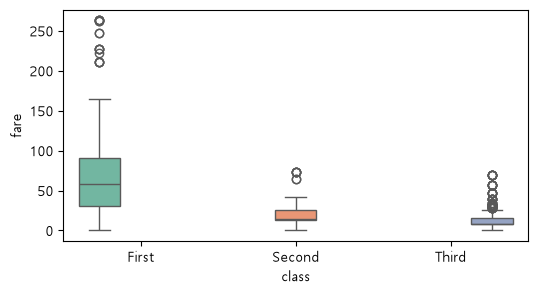

In [22]:
import numpy as np
import pandas as pd
import seaborn as sns # 통계 그래프 라이브러리
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 3))

sns.boxplot(x="class", y="fare", data=df, ax=ax, hue="class", palette="Set2")

# # 산점도
# ax.scatter(df["age"], df["fare"], s=12, alpha=0.6)
# ax.set_title("산점도")
# ax.set(xlabel="나이", ylabel="요금")

In [ ]:
groups = df.loc[df["class"] == "c", "fare"]